In [1]:
import matplotlib.pyplot as plt
import os
import sys
import time
import socket
import threading
import csv
import numpy as np

from datetime import datetime
from ctypes import c_int16, c_int32, byref, c_char_p, c_float

from numpy.core.function_base import linspace
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok


# ---------------------------------------------------------------------
# Local component imports
# ---------------------------------------------------------------------

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp


# ---------------------------------------------------------------------
# Hardware setup
# ---------------------------------------------------------------------

laser = comp.Toptica_Laser()

powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)

powermeter2 = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0046773::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)
# ---------------------------------------------------------------------
# Utility functions
# ---------------------------------------------------------------------

def make_data_folder(base_directory='D:/Data'):
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')

    folder_path = os.path.join(
        base_directory,
        year,
        year_month,
        year_month_day
    )

    os.makedirs(folder_path, exist_ok=True)
    return folder_path


def format_for_filename(x):
    """Keep decimal points in filenames but remove spaces."""
    return str(x).strip().replace(" ", "")


def save_arrays(
        voltage_array,
        time_array,
        commanded_power_mW,
        measured_power_uW,
        iteration,
        gain_value,
        base_directory='D:/Data',
        save_time_once=True
):
    folder_path = make_data_folder(base_directory)
    timestamp = datetime.now().strftime('%H%M%S')

    laserp_str = f"{commanded_power_mW:.3g}"
    measp_str = f"{measured_power_uW:.3g}"
    gain_str = format_for_filename(gain_value)

    suffix = (
        f"laserp_{laserp_str}_mW"
        f"_measp_{measp_str}_uW"
        f"_iter{iteration:03d}"
        f"_gain_{gain_str}"
    )

    voltage_filename = f"pbec_{timestamp}_{suffix}_Voltage.txt"
    voltage_path = os.path.join(folder_path, voltage_filename)

    np.savetxt(voltage_path, voltage_array, fmt='%0.4f')

    time_path = None

    if save_time_once:
        time_filename = "pbec_Time.txt"
        time_path = os.path.join(folder_path, time_filename)

        if not os.path.exists(time_path):
            np.savetxt(time_path, time_array, fmt='%0.4f')

    return voltage_path, time_path

def findThreshold(power, output, min_points=8):


    power = np.asarray(power, dtype=float)
    output = np.asarray(output, dtype=float)

    # Remove invalid values
    valid = np.isfinite(power) & np.isfinite(output)
    power = power[valid]
    output = output[valid]

    if len(power) < 2 * min_points:
        raise ValueError("Not enough data points to determine the threshold.")

    best_error = np.inf
    best_result = None

    # Test every possible threshold position
    for split_index in range(min_points, len(power) - min_points):

        fit_before = np.polyfit(
            power[:split_index],
            output[:split_index],
            1
        )

        fit_after = np.polyfit(
            power[split_index:],
            output[split_index:],
            1
        )

        slope_before, intercept_before = fit_before
        slope_after, intercept_after = fit_after

        # Condensation should produce an increased slope
        if slope_after <= slope_before:
            continue

        prediction_before = np.polyval(
            fit_before,
            power[:split_index]
        )

        prediction_after = np.polyval(
            fit_after,
            power[split_index:]
        )

        error_before = np.sum(
            (output[:split_index] - prediction_before) ** 2
        )

        error_after = np.sum(
            (output[split_index:] - prediction_after) ** 2
        )

        total_error = error_before + error_after

        if total_error < best_error:
            best_error = total_error
            best_result = (
                split_index,
                fit_before,
                fit_after
            )

    if best_result is None:
        raise RuntimeError(
            "No clear increase in slope was found."
        )

    split_index, fit_before, fit_after = best_result

    slope_before, intercept_before = fit_before
    slope_after, intercept_after = fit_after

    # Intersection of the two fitted lines
    threshold = (
        intercept_before - intercept_after
    ) / (
        slope_after - slope_before
    )

    # Use the split position if the intersection is outside the data range
    lower_bound = power[split_index - 1]
    upper_bound = power[split_index]

    if not lower_bound <= threshold <= upper_bound:
        threshold = 0.5 * (lower_bound + upper_bound)

    return threshold, fit_before, fit_after, split_index

In [4]:
laser.set(0)

In [90]:
power_output_list = []
power_output_list_y = []
#get list of power around power threshhold


power_list1 = np.linspace(0.040, 0.040, 5)
power_list2 = np.linspace(0.035,0.037, 50)
power_list = np.concatenate((power_list1,power_list2))
#taking power from both beam path simultaneously
for x in power_list:
    print('Power is :',x*1000, 'mW')
    laser.set(x)
    power_reading = []
    power_reading_y = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        power_output_list.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
    power_output_list_y.append(np.mean(np.array(power_reading_y)))

power_output_array = np.asarray(power_output_list)
power_output_array_y = np.asarray(power_output_list_y)

# Use the total measured output to determine the condensation threshold
total_power_output = (
    power_output_array + power_output_array_y
)

threshold, fit_before, fit_after, split_index = findThreshold(
    power_list,
    total_power_output,
    min_points=8
)
print("\nEstimated condensation threshold:")
print(f"P_threshold = {threshold:.6f}")
print(f"P_threshold = {threshold * 1000:.3f} mW")

print(power_output_list)
print(power_output_list_y)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)
plt.plot(power_list, power_output_list_y)

Power is : 40.0 mW


TopticaBackendError: backend exception: 'timeout during read' ('timeout during read')

Power is : 22.0 mW
Power is : 22.08080808080808 mW
Power is : 22.16161616161616 mW
Power is : 22.242424242424242 mW
Power is : 22.32323232323232 mW
Power is : 22.4040404040404 mW
Power is : 22.48484848484848 mW
Power is : 22.565656565656564 mW
Power is : 22.646464646464644 mW
Power is : 22.727272727272723 mW
Power is : 22.808080808080806 mW
Power is : 22.88888888888889 mW
Power is : 22.96969696969697 mW
Power is : 23.050505050505052 mW
Power is : 23.13131313131313 mW
Power is : 23.21212121212121 mW
Power is : 23.29292929292929 mW
Power is : 23.373737373737374 mW
Power is : 23.454545454545453 mW
Power is : 23.535353535353533 mW
Power is : 23.616161616161616 mW
Power is : 23.696969696969695 mW
Power is : 23.777777777777775 mW
Power is : 23.858585858585858 mW
Power is : 23.939393939393938 mW
Power is : 24.020202020202017 mW
Power is : 24.1010101010101 mW
Power is : 24.18181818181818 mW
Power is : 24.26262626262626 mW
Power is : 24.34343434343434 mW
Power is : 24.424242424242426 mW
Power i

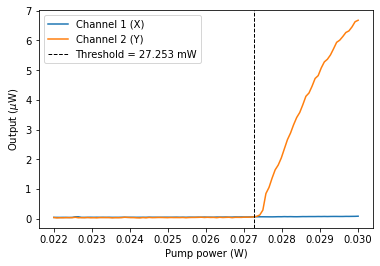

In [2]:
power_output_list = []
power_output_list_y = []
# get list of power around power threshold

power_list = np.linspace(0.022, 0.030, 100)
# taking power from both beam path simultaneously
for x in power_list:
    print('Power is :', x*1000, 'mW')
    laser.set(x)
    power_reading = []
    power_reading_y = []
    for k in range(1):
        power_reading.append(10**6 * powermeter.take_power_reading())
        power_output_list.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6 * powermeter2.take_power_reading())
    power_output_list_y.append(np.mean(np.array(power_reading_y)))

power_output_array = np.asarray(power_output_list)
power_output_array_y = np.asarray(power_output_list_y)

print(power_output_list)
print(power_output_list_y)
laser.set(0)

# ================== 凝聚阈值判定 ==================
def find_threshold(p, y, n_bg=15, n_sigma=5, n_consec=3):
    """
    p: 泵浦功率数组; y: 输出强度数组
    n_bg:     用扫描起始多少个点估计背景（默认前15点，应处于阈值以下）
    n_sigma:  超过背景多少倍噪声算作"开始凝聚"
    n_consec: 需要连续多少个点都超标，防止单点尖峰误判
    返回 (阈值功率, 阈值索引)；未达到阈值返回 (None, None)
    """
    p, y = np.asarray(p), np.asarray(y)
    bg_mean = np.mean(y[:n_bg])
    bg_std  = max(np.std(y[:n_bg]), 1e-12)
    above = y > bg_mean + n_sigma * bg_std
    for i in range(n_bg, len(y) - n_consec + 1):
        if above[i:i + n_consec].all():
            return p[i], i
    return None, None

def fit_threshold(p, y, idx, n_fit=10):
    """阈值以上取 n_fit 个点做线性拟合, 外推与背景延长线的交点(经典两段线性法)"""
    if idx is None or idx + n_fit > len(p):
        return None
    p, y = np.asarray(p), np.asarray(y)
    k, b = np.polyfit(p[idx:idx + n_fit], y[idx:idx + n_fit], 1)
    bg = np.mean(y[:idx])
    return (bg - b) / k if k > 0 else None

th1, i1 = find_threshold(power_list, power_output_array)
th2, i2 = find_threshold(power_list, power_output_array_y)

candidates = [(t, i, name) for t, i, name in
              [(th1, i1, '通道1 (X)'), (th2, i2, '通道2 (Y)')] if t is not None]

if candidates:
    th, idx, first_ch = min(candidates, key=lambda c: c[0])
    th_fit = fit_threshold(power_list,
                           power_output_array if first_ch.startswith('通道1')
                           else power_output_array_y, idx)
    print('=' * 45)
    print(f'本次测量凝聚阈值: {th*1000:.3f} mW  (率先凝聚: {first_ch})')
    if th1 is not None: print(f'  通道1 起始凝聚: {th1*1000:.3f} mW')
    if th2 is not None: print(f'  通道2 起始凝聚: {th2*1000:.3f} mW')
    if th_fit is not None:
        print(f'  线性外推拟合阈值: {th_fit*1000:.3f} mW')
    print('=' * 45)
else:
    th = None
    print('=' * 45)
    print('本次扫描范围内两个通道均未观察到凝聚 (未达阈值)')
    print('=' * 45)

import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list, label='Channel 1 (X)')
plt.plot(power_list, power_output_list_y, label='Channel 2 (Y)')
if th is not None:
    plt.axvline(th, color='k', ls='--', lw=1,
                label=f'Threshold = {th*1000:.3f} mW')
plt.xlabel('Pump power (W)')
plt.ylabel('Output ($\\mu$W)')
plt.legend()
plt.show()

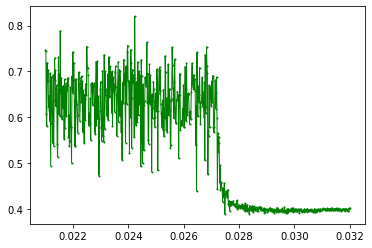

In [11]:
dataz = np.sqrt((np.array(power_output_list_y))/(np.array(power_output_list))-0.04)



plt.figure()
#plt.plot(power_list, datax, marker='o', color='r', markersize=1, linewidth=1)
#plt.plot(power_list, datay, marker='o', color='b', markersize=1, linewidth=1)
plt.plot(power_list, dataz, marker='o', color='g', markersize=1, linewidth=1)
plt.show()

In [20]:
laser.set(0.020)

Power is : 22.0 mW
Power is : 22.050251256281406 mW
Power is : 22.100502512562812 mW
Power is : 22.15075376884422 mW
Power is : 22.201005025125628 mW
Power is : 22.251256281407034 mW
Power is : 22.30150753768844 mW
Power is : 22.351758793969847 mW
Power is : 22.402010050251256 mW
Power is : 22.452261306532662 mW
Power is : 22.50251256281407 mW
Power is : 22.552763819095475 mW
Power is : 22.60301507537688 mW
Power is : 22.65326633165829 mW
Power is : 22.703517587939697 mW
Power is : 22.753768844221103 mW
Power is : 22.80402010050251 mW
Power is : 22.85427135678392 mW
Power is : 22.904522613065325 mW
Power is : 22.95477386934673 mW
Power is : 23.005025125628137 mW
Power is : 23.055276381909547 mW
Power is : 23.105527638190953 mW
Power is : 23.15577889447236 mW
Power is : 23.206030150753765 mW
Power is : 23.256281407035175 mW
Power is : 23.30653266331658 mW
Power is : 23.356783919597987 mW
Power is : 23.407035175879397 mW
Power is : 23.457286432160803 mW
Power is : 23.507537688442213 mW
P

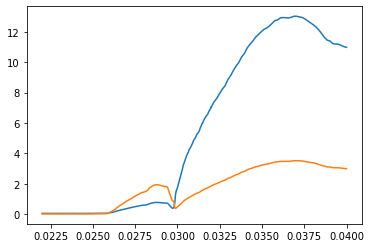

In [3]:
power_output_list = []
power_output_list_y = []
#get list of power around power threshhold


power_list1 = np.linspace(0.022,0.032, 200)
power_list2 = np.linspace(0.032,0.040, 50)
power_list = np.concatenate((power_list1,power_list2))
#taking power from both beam path simultaneously
for x in power_list:
    print('Power is :',x*1000, 'mW')
    laser.set(x)
    power_reading = []
    power_reading_y = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        power_output_list.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
    power_output_list_y.append(np.mean(np.array(power_reading_y)))

print(power_list)
print(power_output_list)
print(power_output_list_y)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)
plt.plot(power_list, power_output_list_y)

Power is : 22.0 mW
Power is : 22.050251256281406 mW
Power is : 22.100502512562812 mW
Power is : 22.15075376884422 mW
Power is : 22.201005025125628 mW
Power is : 22.251256281407034 mW
Power is : 22.30150753768844 mW
Power is : 22.351758793969847 mW
Power is : 22.402010050251256 mW
Power is : 22.452261306532662 mW
Power is : 22.50251256281407 mW
Power is : 22.552763819095475 mW
Power is : 22.60301507537688 mW
Power is : 22.65326633165829 mW
Power is : 22.703517587939697 mW
Power is : 22.753768844221103 mW
Power is : 22.80402010050251 mW
Power is : 22.85427135678392 mW
Power is : 22.904522613065325 mW
Power is : 22.95477386934673 mW
Power is : 23.005025125628137 mW
Power is : 23.055276381909547 mW
Power is : 23.105527638190953 mW
Power is : 23.15577889447236 mW
Power is : 23.206030150753765 mW
Power is : 23.256281407035175 mW
Power is : 23.30653266331658 mW
Power is : 23.356783919597987 mW
Power is : 23.407035175879397 mW
Power is : 23.457286432160803 mW
Power is : 23.507537688442213 mW
P

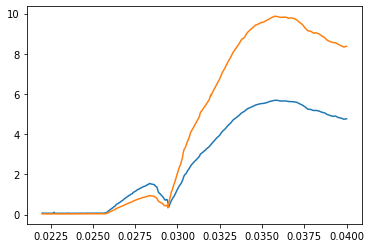

In [4]:
power_output_list = []
power_output_list_y = []
#get list of power around power threshhold


power_list1 = np.linspace(0.022,0.032, 200)
power_list2 = np.linspace(0.032,0.040, 50)
power_list = np.concatenate((power_list1,power_list2))
#taking power from both beam path simultaneously
for x in power_list:
    print('Power is :',x*1000, 'mW')
    laser.set(x)
    power_reading = []
    power_reading_y = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        power_output_list.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
    power_output_list_y.append(np.mean(np.array(power_reading_y)))

print(power_list)
print(power_output_list)
print(power_output_list_y)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)
plt.plot(power_list, power_output_list_y)

Power is : 22.0 mW
Power is : 22.050251256281406 mW
Power is : 22.100502512562812 mW
Power is : 22.15075376884422 mW
Power is : 22.201005025125628 mW
Power is : 22.251256281407034 mW
Power is : 22.30150753768844 mW
Power is : 22.351758793969847 mW
Power is : 22.402010050251256 mW
Power is : 22.452261306532662 mW
Power is : 22.50251256281407 mW
Power is : 22.552763819095475 mW
Power is : 22.60301507537688 mW
Power is : 22.65326633165829 mW
Power is : 22.703517587939697 mW
Power is : 22.753768844221103 mW
Power is : 22.80402010050251 mW
Power is : 22.85427135678392 mW
Power is : 22.904522613065325 mW
Power is : 22.95477386934673 mW
Power is : 23.005025125628137 mW
Power is : 23.055276381909547 mW
Power is : 23.105527638190953 mW
Power is : 23.15577889447236 mW
Power is : 23.206030150753765 mW
Power is : 23.256281407035175 mW
Power is : 23.30653266331658 mW
Power is : 23.356783919597987 mW
Power is : 23.407035175879397 mW
Power is : 23.457286432160803 mW
Power is : 23.507537688442213 mW
P

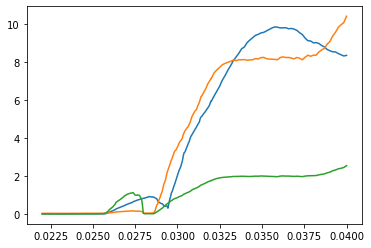

In [5]:
plt.plot(power_list, power_output_list_y)
power_output_list = []
power_output_list_y = []
#get list of power around power threshhold


power_list1 = np.linspace(0.022, 0.032, 200)
power_list2 = np.linspace(0.032, 0.040, 50)
power_list = np.concatenate((power_list1, power_list2))
#taking power from both beam path simultaneously
for x in power_list:
    print('Power is :', x * 1000, 'mW')
    laser.set(x)
    power_reading = []
    power_reading_y = []
    for k in range(1):
        power_reading.append(10 ** 6 * powermeter.take_power_reading())
        power_output_list.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10 ** 6 * powermeter2.take_power_reading())
    power_output_list_y.append(np.mean(np.array(power_reading_y)))

print(power_list)
print(power_output_list)
print(power_output_list_y)
laser.set(0)
import matplotlib.pyplot as plt

plt.plot(power_list, power_output_list)
plt.plot(power_list, power_output_list_y)

Power is : 35.0 mW
Power is : 35.03355704697987 mW
Power is : 35.06711409395973 mW
Power is : 35.1006711409396 mW
Power is : 35.13422818791947 mW
Power is : 35.16778523489933 mW
Power is : 35.2013422818792 mW
Power is : 35.234899328859065 mW
Power is : 35.26845637583892 mW
Power is : 35.302013422818796 mW
Power is : 35.33557046979866 mW
Power is : 35.369127516778526 mW
Power is : 35.40268456375839 mW
Power is : 35.43624161073826 mW
Power is : 35.46979865771813 mW
Power is : 35.50335570469799 mW
Power is : 35.53691275167785 mW
Power is : 35.570469798657726 mW
Power is : 35.604026845637584 mW
Power is : 35.63758389261745 mW
Power is : 35.67114093959732 mW
Power is : 35.70469798657718 mW
Power is : 35.73825503355705 mW
Power is : 35.77181208053692 mW
Power is : 35.80536912751678 mW
Power is : 35.83892617449665 mW
Power is : 35.872483221476514 mW
Power is : 35.90604026845637 mW
Power is : 35.939597315436245 mW
Power is : 35.97315436241611 mW
Power is : 36.006711409395976 mW
Power is : 36.0

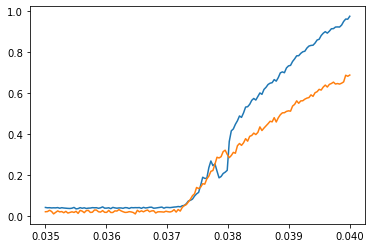

In [27]:
power_output_list = []
power_output_list_y = []
#get list of power around power threshhold


power_list = np.linspace(0.035, 0.040, 150)

#taking power from both beam path simultaneously
for x in power_list:
    print('Power is :',x*1000, 'mW')
    laser.set(x)
    power_reading = []
    power_reading_y = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        power_output_list.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
    power_output_list_y.append(np.mean(np.array(power_reading_y)))

print(power_list)
print(power_output_list)
print(power_output_list_y)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)
plt.plot(power_list, power_output_list_y)

In [2]:
laser.set(0.06)

NameError: name 'laser' is not defined